# Marketing Campaign Performance & Conversion Analytics

## Project Overview
This project analyzes a Portuguese bank's phone-based direct marketing campaign (May 2008 to November 2010) to understand which customers, channels, and contact strategies lead to term-deposit subscriptions.

- **Dataset:** UCI Bank Marketing dataset (45,211 contacts, 17 original fields). Moro, Laureano & Cortez (2011).
- **Goal:** Measure conversion performance and identify where marketing effort is most and least effective.
- **Workflow:** Excel (first-pass cleaning and PivotTables) → **Python (validation and analysis, this notebook)** → SQL → Tableau.
- **Note on cost:** The dataset has no real campaign cost. Cost per acquisition (CPA) uses an assumed $0.50 per minute of call time, so CPA figures are estimates and are best used to compare segments.

## 1. Load Dataset

Import libraries and load the cleaned dataset for analysis.

In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_excel(
    "bank_marketing_cleaned.xlsx",
    sheet_name="Cleaned_Data"
)


In [3]:
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

## 2. Data Inspection
Check the size, column types, and a sample of rows to confirm the data loaded correctly (expected: 45,211 rows and 23 columns).

In [4]:
print(df.shape)
print(df.head())
print(df.info())


(45211, 23)
   age           job  marital  education default  balance housing loan  Channel  day month  duration  campaign  pdays  \
0   58    management  married   tertiary      no     2143     yes   no  unknown    5   may       261         1     -1   
1   44    technician   single  secondary      no       29     yes   no  unknown    5   may       151         1     -1   
2   33  entrepreneur  married  secondary      no        2     yes  yes  unknown    5   may        76         1     -1   
3   47   blue-collar  married    unknown      no     1506     yes   no  unknown    5   may        92         1     -1   
4   33       unknown   single    unknown      no        1      no   no  unknown    5   may       198         1     -1   

   previous poutcome Converted  Duration_Minutes Age_Band Prior_Contacted  Converted_Flag Campaign_Bucket  \
0         0  unknown        no          4.350000      56+              No               0       1 contact   
1         0  unknown        no          2.5

## 3. Data Quality Checks
Verify there are no missing values or duplicate rows, and re-check that `Converted_Flag` matches the `Converted` yes/no labels, so the Excel calculations are confirmed independently in Python.

In [5]:
# 3. Check missing values
print("Total missing cells:", df.isnull().sum().sum())

# 4. Check duplicate records
print("Duplicate rows:", df.duplicated().sum())

# 5. Check conversion labels
print("\nConversion labels:")
print(df["Converted"].value_counts(dropna=False))

# 6. Validate conversion flag
expected_flag = df["Converted"].str.lower().eq("yes").astype(int)
print(
    "Incorrect conversion flags:",
    (expected_flag != df["Converted_Flag"]).sum()
)

Total missing cells: 0
Duplicate rows: 0

Conversion labels:
Converted
no     39922
yes     5289
Name: count, dtype: int64
Incorrect conversion flags: 0


## 4. Key Performance Indicators

Calculate total contacts, subscriptions, non-conversions, conversion rate, and average call duration.

In [6]:

total_contacts = len(df)
total_conversions = df["Converted_Flag"].sum()
conversion_rate = df["Converted_Flag"].mean() * 100
avg_call_minutes = df["Duration_Minutes"].mean()

kpis = pd.DataFrame({
    "Metric": [
        "Total Contacts",
        "Successful Subscriptions",
        "Non-Conversions",
        "Conversion Rate (%)",
        "Average Call Duration (Minutes)"
    ],
    "Value": [
        (total_contacts),
        (total_conversions),
        (total_contacts - total_conversions),
        round(conversion_rate, 2),
        round(avg_call_minutes, 2)
    ]
})

display(kpis)


,Metric,Value
0,Total Contacts,45211.0
1,Successful Subscriptions,5289.0
2,Non-Conversions,39922.0
3,Conversion Rate (%),11.7
4,Average Call Duration (Minutes),4.3


## 5. Conversion by Channel

Compare conversion rates across contact channels to evaluate campaign performance.

In [7]:

channel_analysis = (
    df.groupby("Channel")
      .agg(
          Total_Contacts=("Converted_Flag", "size"),
          Successful_Conversions=("Converted_Flag", "sum"),
          Conversion_Rate=("Converted_Flag", "mean")
      )
      .reset_index()
)

channel_analysis["Conversion_Rate"] *= 100

channel_analysis = channel_analysis.sort_values(
    "Conversion_Rate", ascending=False
)

display(channel_analysis.round(2))


,Channel,Total_Contacts,Successful_Conversions,Conversion_Rate
0,cellular,29285,4369,14.92
1,telephone,2906,390,13.42
2,unknown,13020,530,4.07


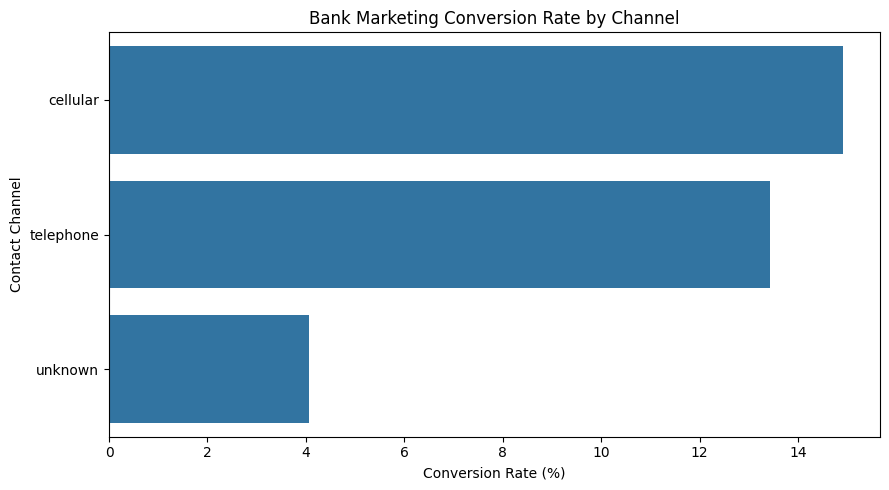

In [8]:

plt.figure(figsize=(9, 5))

sns.barplot(
    data=channel_analysis,
    x="Conversion_Rate",
    y="Channel"
)

plt.title("Bank Marketing Conversion Rate by Channel")
plt.xlabel("Conversion Rate (%)")
plt.ylabel("Contact Channel")
plt.tight_layout()
plt.show()


## 6. Conversion by Job

Analyze subscription rates across different customer job categories.

In [9]:

job_analysis = (
    df.groupby("job")
      .agg(
          Total_Contacts=("Converted_Flag", "size"),
          Conversions=("Converted_Flag", "sum"),
          Conversion_Rate=("Converted_Flag", "mean")
      )
      .reset_index()
)

job_analysis["Conversion_Rate"] *= 100
job_analysis = job_analysis.sort_values(
    "Conversion_Rate", ascending=False
)

display(job_analysis.round(2))


,job,Total_Contacts,Conversions,Conversion_Rate
8,student,938,269,28.68
5,retired,2264,516,22.79
10,unemployed,1303,202,15.50
4,management,9458,1301,13.76
0,admin.,5171,631,12.20
6,self-employed,1579,187,11.84
11,unknown,288,34,11.81
9,technician,7597,840,11.06
7,services,4154,369,8.88
3,housemaid,1240,109,8.79


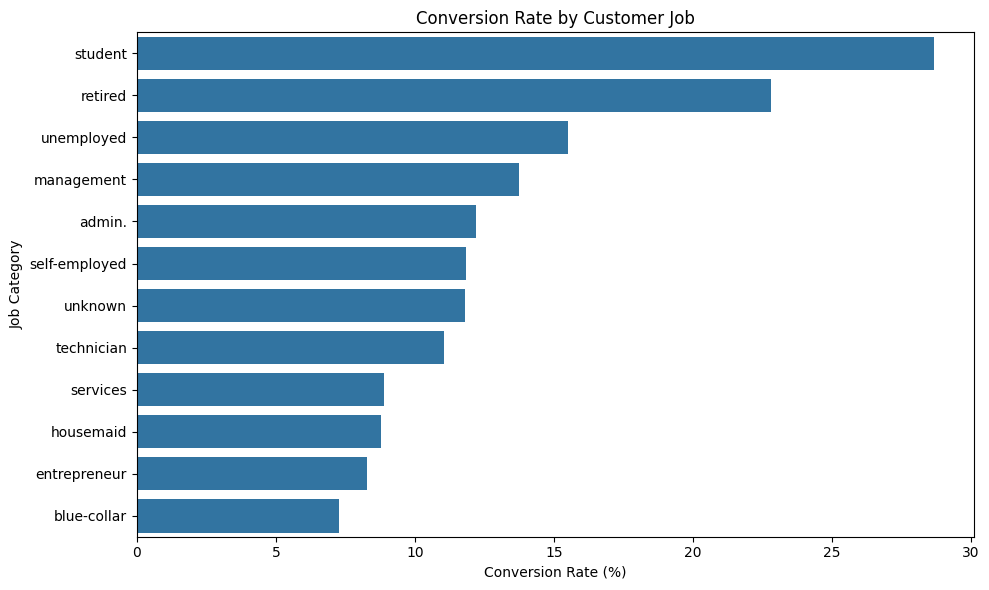

In [10]:

plt.figure(figsize=(10, 6))

sns.barplot(
    data=job_analysis,
    x="Conversion_Rate",
    y="job"
)

plt.title("Conversion Rate by Customer Job")
plt.xlabel("Conversion Rate (%)")
plt.ylabel("Job Category")
plt.tight_layout()
plt.show()


## 7. Conversion by Age Band
Check how response changes across age groups.

In [11]:

age_analysis = (
    df.groupby("Age_Band", observed=False)
      .agg(
          Total_Contacts=("Converted_Flag", "size"),
          Conversions=("Converted_Flag", "sum"),
          Conversion_Rate=("Converted_Flag", "mean")
      )
      .reset_index()
)

age_analysis["Conversion_Rate"] *= 100
display(age_analysis.round(2))


,Age_Band,Total_Contacts,Conversions,Conversion_Rate
0,18-25,1336,320,23.95
1,26-35,15571,1869,12.00
2,36-45,13856,1301,9.39
3,46-55,9548,893,9.35
4,56+,4900,906,18.49


## 8. Monthly Conversion Trend
Look at how conversion varies across the campaign calendar (months shown in calendar order).

In [12]:

month_order = [
    "jan", "feb", "mar", "apr", "may", "jun",
    "jul", "aug", "sep", "oct", "nov", "dec"
]

month_analysis = (
    df.groupby("month")
      .agg(
          Total_Contacts=("Converted_Flag", "size"),
          Conversions=("Converted_Flag", "sum"),
          Conversion_Rate=("Converted_Flag", "mean")
      )
      .reindex(month_order)
      .reset_index()
)

month_analysis["Conversion_Rate"] *= 100

display(month_analysis.round(2))


,month,Total_Contacts,Conversions,Conversion_Rate
0,jan,1403,142,10.12
1,feb,2649,441,16.65
2,mar,477,248,51.99
3,apr,2932,577,19.68
4,may,13766,925,6.72
5,jun,5341,546,10.22
6,jul,6895,627,9.09
7,aug,6247,688,11.01
8,sep,579,269,46.46
9,oct,738,323,43.77


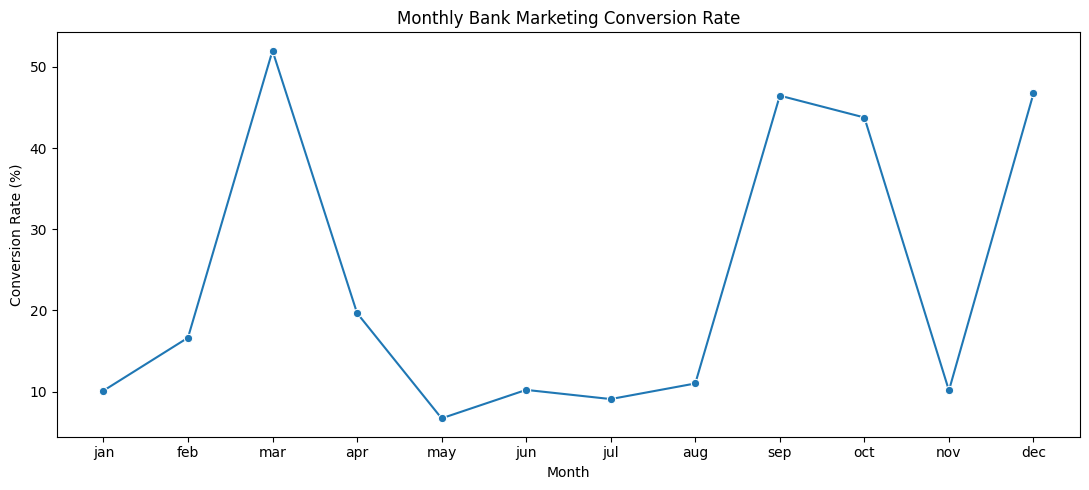

In [13]:

plt.figure(figsize=(11, 5))

sns.lineplot(
    data=month_analysis,
    x="month",
    y="Conversion_Rate",
    marker="o"
)

plt.title("Monthly Bank Marketing Conversion Rate")
plt.xlabel("Month")
plt.ylabel("Conversion Rate (%)")
plt.tight_layout()
plt.show()


## 9. Contact Attempts vs Conversion
Group clients by the number of contacts in this campaign (1, 2-3, 4+) to test whether repeated calling keeps paying off.

In [14]:

campaign_analysis = (
    df.groupby("Campaign_Bucket")
      .agg(
          Total_Contacts=("Converted_Flag", "size"),
          Conversions=("Converted_Flag", "sum"),
          Conversion_Rate=("Converted_Flag", "mean")
      )
      .reset_index()
)

campaign_analysis["Conversion_Rate"] *= 100

display(campaign_analysis.round(2))


,Campaign_Bucket,Total_Contacts,Conversions,Conversion_Rate
0,1 contact,17544,2561,14.60
1,2-3 contacts,18026,2019,11.20
2,4+ contacts,9641,709,7.35


## 10. Cost per Acquisition and Previous Campaign Outcome
Estimate cost per acquisition (CPA) by channel using the assumed $0.50 per call minute, and check how previous campaign results and prior contact relate to conversion.

In [15]:
# Overall estimated CPA (assumes $0.50 per call minute)
overall_cpa = df["Estimated_Cost"].sum() / df["Converted_Flag"].sum()
print(f"Overall estimated CPA: ${overall_cpa:.2f}")

# CPA by channel
cpa_by_channel = (
    df.groupby("Channel")
      .agg(Total_Cost=("Estimated_Cost", "sum"),
           Conversions=("Converted_Flag", "sum"))
)
cpa_by_channel["Estimated_CPA"] = (
    cpa_by_channel["Total_Cost"] / cpa_by_channel["Conversions"]
).round(2)
display(cpa_by_channel.round(2))

# Previous campaign outcome
poutcome_analysis = (
    df.groupby("poutcome")
      .agg(Total_Contacts=("Converted_Flag", "size"),
           Conversions=("Converted_Flag", "sum"),
           Conversion_Rate=("Converted_Flag", "mean"))
      .reset_index()
)
poutcome_analysis["Conversion_Rate"] *= 100
display(poutcome_analysis.sort_values("Conversion_Rate", ascending=False).round(2))

# Previously contacted vs new clients
prior_analysis = (
    df.groupby("Prior_Contacted")["Converted_Flag"]
      .mean().mul(100).round(2)
      .rename("Conversion_Rate_%")
)
display(prior_analysis)

Overall estimated CPA: $18.39


,Total_Cost,Conversions,Estimated_CPA
Channel,,,
cellular,64186.37,4369,14.69
telephone,5699.78,390,14.61
unknown,27378.94,530,51.66


,poutcome,Total_Contacts,Conversions,Conversion_Rate
2,success,1511,978,64.73
1,other,1840,307,16.68
0,failure,4901,618,12.61
3,unknown,36959,3386,9.16


Prior_Contacted
No      9.16
Yes    23.07
Name: Conversion_Rate_%, dtype: float64

## 11. Export for SQL
Save the validated dataset as a CSV, which is loaded into MySQL for the SQL analysis stage.

In [16]:

df.to_csv(
    "bank_marketing_python_cleaned.csv",
    index=False
)

print("Cleaned dataset exported successfully.")

Cleaned dataset exported successfully.


## Key Findings

1. **Overall performance:** 5,289 of 45,211 contacts subscribed, a **11.7%** conversion rate. Estimated CPA is about **$18.39** under the $0.50/min cost assumption.
2. **Channel:** Cellular contacts convert best (**14.9%**), followed by telephone (13.4%). Contacts with an unknown channel convert at only **4.1%** and cost about 3.5x more per conversion than cellular.
3. **Diminishing returns on repeat calls:** Conversion falls from **14.6%** with one contact to **11.2%** with 2-3 contacts and **7.4%** with 4+ contacts, so extra attempts yield progressively less.
4. **Previous campaign success:** Clients who subscribed in a previous campaign convert at **64.7%**, far above the 9.2% for clients with no previous outcome. Previously contacted clients overall convert at 23.1% versus 9.2% for new ones.
5. **Customer segments:** Students (**28.7%**) and retirees (**22.8%**) respond best. Blue-collar workers respond worst (**7.3%**). By age, the 18-25 (24.0%) and 56+ (18.5%) bands outperform the 26-55 groups.
6. **Timing:** May carries the most contacts (13,766) but converts at only **6.7%**, while the smaller months of March (52.0%), December (46.7%), September (46.5%) and October (43.8%) convert far higher.

## Business Recommendations
- Prioritize **cellular** contacts and investigate why "unknown"-channel contacts perform so poorly.
- **Cap contact attempts** at about 2-3 per client and redirect that effort to new, higher-propensity prospects.
- Target **students, retirees, and previously successful clients**, which are the cheapest segments to convert.
- Review the **May-heavy** calling schedule, since the busiest month produced weak returns.

*Limitations: CPA relies on an assumed cost per minute; the data is observational, so these patterns show association, not proof of cause.*